In [1]:
import duckdb, numpy as np, matplotlib.pyplot as plt
con = duckdb.connect("../data/basket.duckdb", read_only=True)
sizes = con.execute("""
    SELECT COUNT(*) AS n FROM order_products__prior GROUP BY order_id
""").df().n.values
rng = np.random.default_rng(7)
true_mean = sizes.mean()   # we know the truth because we have every order

def boot(x, stat=np.mean, B=5000):
    idx = rng.integers(0, len(x), size=(B, len(x)))   # resample with replacement
    return stat(x[idx], axis=1)

true mean:        10.09
sample mean:      10.23
bootstrap 95% CI: [9.25, 11.29]
formula 95% CI:   [9.19, 11.28]


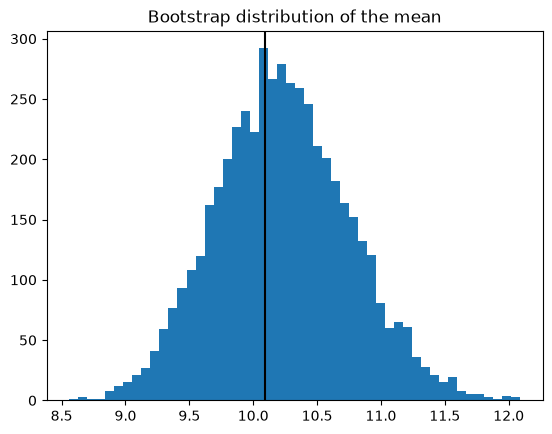

In [2]:
sample = rng.choice(sizes, 200)          # pretend this is all you could afford to collect
b = boot(sample)
lo, hi = np.percentile(b, [2.5, 97.5])
se = sample.std(ddof=1) / np.sqrt(len(sample))
print(f"true mean:        {true_mean:.2f}")
print(f"sample mean:      {sample.mean():.2f}")
print(f"bootstrap 95% CI: [{lo:.2f}, {hi:.2f}]")
print(f"formula 95% CI:   [{sample.mean()-1.96*se:.2f}, {sample.mean()+1.96*se:.2f}]")
plt.hist(b, bins=50); plt.axvline(true_mean, color="k"); plt.title("Bootstrap distribution of the mean"); plt.show()

In [3]:
bm = boot(sample, np.median)
print("median 95% CI:", np.percentile(bm, [2.5, 97.5]))

median 95% CI: [8. 9.]


In [4]:
def coverage(pop, n, trials=500, B=1000):
    mu = pop.mean(); hb = hf = 0
    for _ in range(trials):
        s = rng.choice(pop, n)
        lo, hi = np.percentile(boot(s, B=B), [2.5, 97.5])
        hb += lo <= mu <= hi
        se = s.std(ddof=1) / np.sqrt(n)
        hf += abs(s.mean() - mu) <= 1.96 * se
    return hb / trials, hf / trials

print("basket size, n=200  (bootstrap, formula):", coverage(sizes, 200))
prod = con.execute("SELECT COUNT(*) AS n FROM order_products__prior GROUP BY product_id").df().n.values
print("product popularity, n=30 (bootstrap, formula):", coverage(prod, 30))

basket size, n=200  (bootstrap, formula): (np.float64(0.962), np.float64(0.962))
product popularity, n=30 (bootstrap, formula): (np.float64(0.606), np.float64(0.594))
